# A self-driving lab on a computer: H2 PSA on activated carbon

A closed loop in the spirit of an autonomous flow-chemistry lab, with RUPTURA as the robot. `ruptura.selfdriving` holds
the technique: `PressureSwingCycle` builds a five-step PSA cycle with product backfill on the column of a base input,
runs it through the Python interface to its cyclic steady state, and turns the phase records into purity, recovery, and
productivity (the robot and its inline analytics); `Campaign` proposes batches of eight setups by batch Bayesian
optimization (the brain), runs them in parallel processes, and keeps the lab notebook, `campaign/experiments.csv`.

Here the feed is the 40/30/30 CO2/N2/H2 mixture of experiment T15 of Marx et al. on its activated carbon
(`examples/PSA-H2-activated-carbon`). The campaign maximizes the H2 productivity and recovery, both net of the H2 used
for purge and backfill, under H2 purity of at least 99.9 %, over eight variables: temperature, adsorption and purge
pressure, feed velocity, step time, purge-to-feed ratio, column length (at the sorbent mass of T15), and backfill share.
The docstrings of `ruptura.selfdriving.psa` give the equations. The figures are sized for panels printed at half the
text width of the RUPTURA 2.0 paper.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ruptura.selfdriving import Campaign, PressureSwingCycle, hypervolume, pareto_front

plt.rcParams.update({
    "figure.figsize": (8, 6),
    # The panels are printed at 0.49 of the A4 text width (3.07 in), i.e. at 38% of their 8 in width.
    # These sizes print as 8.1 pt (ticks, legends) and 8.8 pt (axis labels).
    "font.size": 23,
    "axes.labelsize": 23,
    "axes.titlesize": 25,
    "xtick.labelsize": 21,
    "ytick.labelsize": 21,
    "legend.fontsize": 21,
    "legend.title_fontsize": 21,
    "axes.labelpad": 6.0,
    "lines.linewidth": 3.0,
    "lines.markersize": 13,
    "lines.markeredgewidth": 1.8,
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "xtick.minor.width": 1.0,
    "ytick.minor.width": 1.0,
    "legend.handlelength": 1.2,
    "legend.labelspacing": 0.3,
    "legend.borderaxespad": 0.3,
    "legend.columnspacing": 1.0,
    "axes.grid": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
})
FIGURES = Path.cwd() / "figures"
FIGURES.mkdir(exist_ok=True)

## The campaign

`campaign.run()` runs the rounds that `campaign/experiments.csv` does not have yet: nothing for the finished campaign
of this folder, about 11 min on 8 cores from scratch (delete `campaign/` for that). `campaign.write_inputs()` writes
the input of every experiment of the lab notebook again, and `campaign.rerun()` runs them all again, 8 at a time.

In [2]:
cycle = PressureSwingCycle(Path("..") / "PSA-H2-activated-carbon" / "simulation.json", product="H2",
                           purity_target=0.999)
campaign = Campaign(cycle, Path("campaign"), rounds=15, batch_size=8, workers=8, seed=2026)
campaign.run()
# The search space: bounds and scale of each variable (SI units), and the baseline cycle.
pd.DataFrame({name: [*bounds, cycle.baseline[name]] for name, bounds in cycle.variables.items()},
             index=["lower", "upper", "scale", "baseline"]).T

,lower,upper,scale,baseline
temperature,288.0,328.0,linear,298.0
high_pressure,400000.0,1000000.0,linear,1000000.0
low_pressure,100000.0,200000.0,linear,100000.0
feed_velocity,0.01,0.06,log,0.03
adsorption_time,20.0,200.0,log,30.0
purge_to_feed,0.02,0.6,log,0.266667
length,0.6,3.6,log,1.2
backfill,0.0,1.0,linear,0.0


In [3]:
def load_campaign():
    """The lab notebook of the campaign, with the productivity in mmol/(kg s), the setup on the unit cube of the
    optimizer, and the feasible, Pareto-optimal, and baseline experiments marked."""
    data = pd.read_csv(campaign.log)
    data["productivity_mmol"] = 1.0e3 * data["productivity"]
    unit = cycle.to_unit(data.to_dict("records"))
    for k, name in enumerate(cycle.variables):
        data[f"unit_{name}"] = unit[:, k]
    data["feasible"] = (data["status"] != "failed") & (data["purity"] >= cycle.purity_target)
    feasible = data[data["feasible"]]
    data["pareto"] = False
    data.loc[feasible.index, "pareto"] = pareto_front(feasible[["productivity_mmol", "recovery"]].to_numpy())
    data["baseline"] = np.all([np.isclose(data[name], value) for name, value in cycle.baseline.items()], axis=0)
    return data


def hypervolume_history(data, reference=(0.0, 0.0)):
    """Hypervolume of the feasible experiments in (productivity in mmol/(kg s), recovery) after each experiment."""
    history = []
    for count in range(1, len(data) + 1):
        done = data.iloc[:count]
        points = done.loc[done["feasible"], ["productivity_mmol", "recovery"]].to_numpy()
        history.append(hypervolume(points, np.array(reference)))
    return np.array(history)


results = load_campaign()
pareto = results[results["pareto"]].sort_values("productivity_mmol")
baseline = results[results["baseline"]].iloc[0]
history = hypervolume_history(results)
print(f"{len(results)} experiments, {results['feasible'].sum()} at purity >= {cycle.purity_target}, "
      f"{len(pareto)} on the Pareto front, {(results['status'] != 'converged').sum()} not at the cyclic steady state")
print(f"baseline: productivity {baseline['productivity_mmol']:.3f} mmol/(kg s), recovery {baseline['recovery']:.3f}, "
      f"purity {baseline['purity']:.5f}")
for round_index in sorted(results["round"].unique()):
    done = results["round"] <= round_index
    batch = results[results["round"] == round_index]
    print(f"round {round_index:2d}: hypervolume {history[done.sum() - 1]:.3f}, "
          f"{batch['feasible'].sum()} of {len(batch)} at the target")
columns = ["index", "round", "productivity_mmol", "recovery", "purity", "backfill_to_feed", "cycle_time", "cycles",
           *cycle.variables]
pareto[columns].round(4)

136 experiments, 98 at purity >= 0.999, 5 on the Pareto front, 12 not at the cyclic steady state
baseline: productivity 0.584 mmol/(kg s), recovery 0.150, purity 0.99970
round  0: hypervolume 0.088, 10 of 16 at the target
round  1: hypervolume 0.089, 4 of 8 at the target
round  2: hypervolume 0.188, 6 of 8 at the target
round  3: hypervolume 0.188, 7 of 8 at the target
round  4: hypervolume 0.188, 5 of 8 at the target
round  5: hypervolume 0.188, 5 of 8 at the target
round  6: hypervolume 0.188, 7 of 8 at the target
round  7: hypervolume 0.199, 7 of 8 at the target
round  8: hypervolume 0.242, 7 of 8 at the target
round  9: hypervolume 0.279, 7 of 8 at the target
round 10: hypervolume 0.299, 2 of 8 at the target
round 11: hypervolume 0.299, 8 of 8 at the target
round 12: hypervolume 0.375, 5 of 8 at the target
round 13: hypervolume 0.387, 6 of 8 at the target
round 14: hypervolume 0.393, 4 of 8 at the target
round 15: hypervolume 0.442, 8 of 8 at the target


,index,round,productivity_mmol,recovery,purity,backfill_to_feed,cycle_time,cycles,temperature,high_pressure,low_pressure,feed_velocity,adsorption_time,purge_to_feed,length,backfill
125,125,14,0.8370,0.4378,0.9996,0.0511,402.1119,10,294.7117,1000000.0,100000.0,0.0175,153.9592,0.1193,1.3021,0.0897
121,121,14,0.8600,0.4338,0.9996,0.0537,383.8443,10,294.6217,1000000.0,100000.0,0.0176,147.2131,0.1178,1.2687,0.0933
117,117,13,0.8750,0.4318,0.9998,0.0839,381.9999,10,294.9000,1000000.0,100000.0,0.0180,151.8392,0.1187,1.1873,0.1587
127,127,14,0.8992,0.4277,0.9996,0.1154,379.1397,30,295.1077,1000000.0,100000.0,0.0177,159.1345,0.1220,1.0467,0.2518
128,128,15,1.0175,0.4114,0.9995,0.0771,304.0102,10,294.5439,1000000.0,100000.0,0.0179,123.5036,0.1279,1.0129,0.1425


## Convergence of the campaign

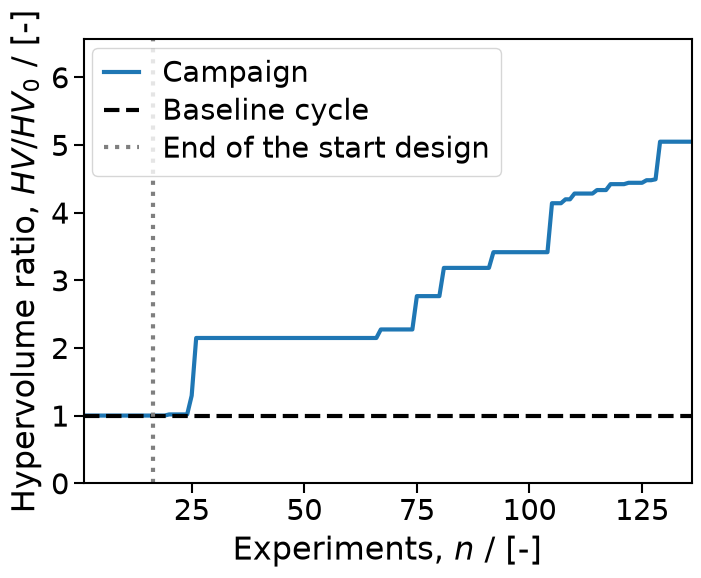

In [4]:
data = load_campaign()
history = hypervolume_history(data)
baseline_index = int(data.index[data["baseline"]][0])
baseline_value = hypervolume(data.loc[[baseline_index], ["productivity_mmol", "recovery"]].to_numpy(), np.zeros(2))
first_round = int((data["round"] == 0).sum())

# Relative to the hypervolume of the baseline cycle alone, the rectangle of its productivity and recovery.
ratio = history / baseline_value

fig, ax = plt.subplots()
ax.plot(np.arange(1, len(history) + 1), ratio, color="C0", label="Campaign")
ax.axhline(1.0, color="k", linestyle="--", label="Baseline cycle")
ax.axvline(first_round + 0.5, color="C7", linestyle=":", label="End of the start design")
ax.set_xlabel("Experiments, $n$ / [-]")
ax.set_ylabel("Hypervolume ratio, $HV/HV_0$ / [-]")
ax.set_xlim(1, len(history))
ax.set_ylim(0.0, 1.3 * ratio.max())
ax.legend(loc="upper left")
# The same plot box as the impurity figure, below it in the paper, whose tick labels are wider.
fig.subplots_adjust(left=0.20, right=0.96, bottom=0.20, top=0.94)
fig.savefig(FIGURES / "hypervolume.pdf", dpi=300)
plt.show()

## Productivity against recovery

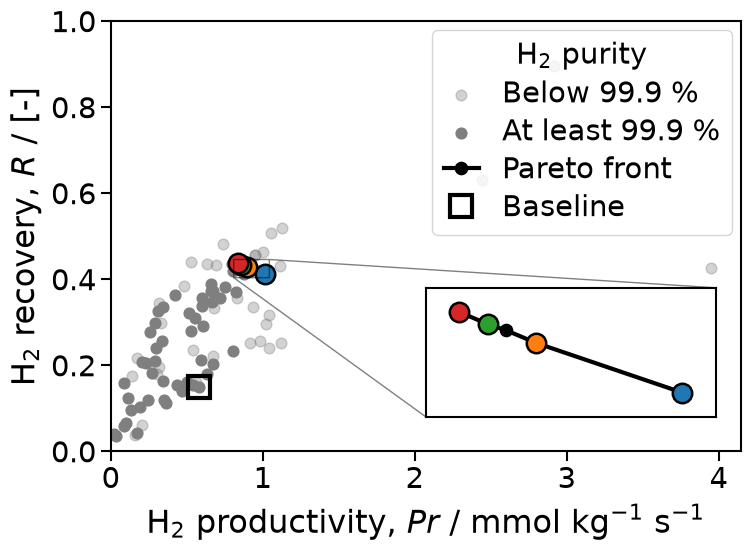

In [5]:
data = load_campaign()
feasible = data[data["feasible"]]
infeasible = data[~data["feasible"] & (data["status"] != "failed")]
front = data[data["pareto"]].sort_values("productivity_mmol")
start = data[data["baseline"]]
target = f"{100 * cycle.purity_target:g} %"
# The setups of the Pareto-front figure, in its colors: up to four, from the most productive one.
ordered = front.sort_values("productivity_mmol", ascending=False)
shown = ordered.iloc[np.unique(np.linspace(0, len(ordered) - 1, min(len(ordered), 4)).round().astype(int))]

fig, ax = plt.subplots()
ax.scatter(infeasible["productivity_mmol"], infeasible["recovery"], s=60, color="C7", alpha=0.35,
           label=f"Below {target}")
ax.scatter(feasible["productivity_mmol"], feasible["recovery"], s=60, color="C7", label=f"At least {target}")
ax.plot(front["productivity_mmol"], front["recovery"], color="k", marker="o", markersize=8, label="Pareto front")
# The front is short: a zoom without ticks (the values are in the legend of the Pareto-front figure) shows its setups.
inset = ax.inset_axes([0.50, 0.08, 0.46, 0.30])
inset.plot(front["productivity_mmol"], front["recovery"], color="k", marker="o", markersize=8)
for k, (_, design) in enumerate(shown.iterrows()):
    for axis in (ax, inset):
        axis.plot(design["productivity_mmol"], design["recovery"], linestyle="none", marker="o", markersize=14,
                  color=f"C{k}", markeredgecolor="k", zorder=3)
x_margin = 0.15 * np.ptp(front["productivity_mmol"])
y_margin = 0.3 * np.ptp(front["recovery"])
inset.set_xlim(front["productivity_mmol"].min() - x_margin, front["productivity_mmol"].max() + x_margin)
inset.set_ylim(front["recovery"].min() - y_margin, front["recovery"].max() + y_margin)
inset.set_xticks([])
inset.set_yticks([])
ax.indicate_inset_zoom(inset, edgecolor="k")
ax.plot(start["productivity_mmol"], start["recovery"], linestyle="none", marker="s", markersize=16,
        markerfacecolor="none", markeredgecolor="k", markeredgewidth=3, label="Baseline")
ax.set_xlabel("H$_2$ productivity, $Pr$ / mmol kg$^{-1}$ s$^{-1}$")
ax.set_ylabel("H$_2$ recovery, $R$ / [-]")
ax.set_xlim(0.0, 1.05 * data["productivity_mmol"].max())
ax.set_ylim(0.0, 1.0)
ax.legend(loc="upper right", title="H$_2$ purity")
fig.tight_layout()
fig.savefig(FIGURES / "pareto_front.pdf", dpi=300)
plt.show()

## Purity of every experiment

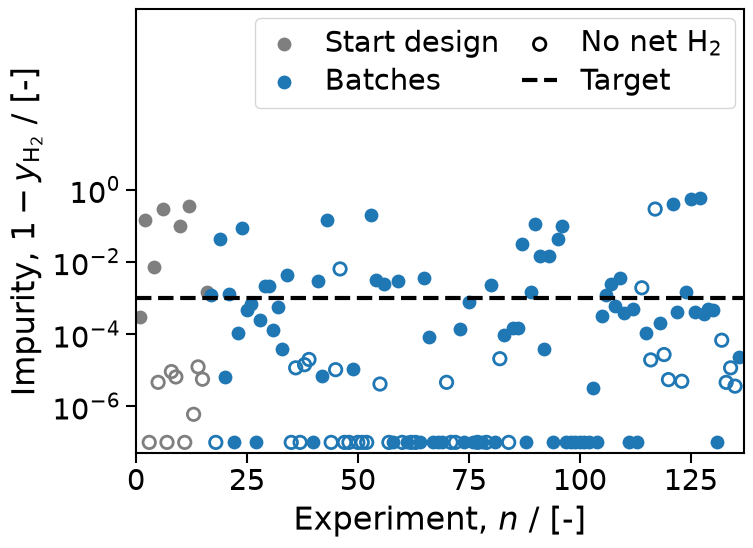

In [6]:
data = load_campaign()
done = data[data["status"] != "failed"]
start = done[done["round"] == 0]
batches = done[done["round"] > 0]
# Below 1e-7 the impurity is integration noise (no N2 leaves the column); such runs are drawn at 1e-7.
floor = 1.0e-7
ticks = [1.0e-6, 1.0e-4, 1.0e-2, 1.0]

fig, ax = plt.subplots()
# A cycle whose purge and backfill take more H2 than it produces (recovery <= 0) flushes the column with H2: its product
# is pure, but there is no net product. Such runs are drawn open.
for group, color, label in ((start, "C7", "Start design"), (batches, "C0", "Batches")):
    net = group["recovery"] > 0.0
    ax.scatter(group.loc[net, "index"] + 1, np.maximum(1.0 - group.loc[net, "purity"], floor), s=80, color=color,
               label=label)
    ax.scatter(group.loc[~net, "index"] + 1, np.maximum(1.0 - group.loc[~net, "purity"], floor), s=80,
               facecolors="none", edgecolors=color, linewidths=2)
ax.scatter([], [], s=80, facecolors="none", edgecolors="k", linewidths=2, label="No net H$_2$")
ax.axhline(1.0 - cycle.purity_target, color="k", linestyle="--", label="Target")
ax.set_yscale("log")
ax.set_yticks(ticks, [r"$10^{-6}$", r"$10^{-4}$", r"$10^{-2}$", r"$10^{0}$"])
ax.set_yticks([], minor=True)
ax.set_ylim(0.5 * floor, 1.0e5)
ax.set_xlabel("Experiment, $n$ / [-]")
ax.set_ylabel(r"Impurity, $1 - y_{\mathrm{H_2}}$ / [-]")
ax.set_xlim(0, len(data) + 1)
ax.legend(loc="upper right", ncol=2, columnspacing=0.8)
# The same plot box as the hypervolume figure, above it in the paper.
fig.subplots_adjust(left=0.20, right=0.96, bottom=0.20, top=0.94)
fig.savefig(FIGURES / "impurity.pdf", dpi=300)
plt.show()

## What the Pareto-optimal cycles look like

Setups along the Pareto front, from the most productive to the one with the highest recovery, on the unit cube of the
optimizer: 0 and 1 are the bounds of each variable, on a log scale for the feed velocity $v_F$, the adsorption time
$t_{\mathrm{ads}}$, the purge-to-feed ratio $G$, and the length $L$; $b$ is the share of the pressurization made with
product H2 (backfill).

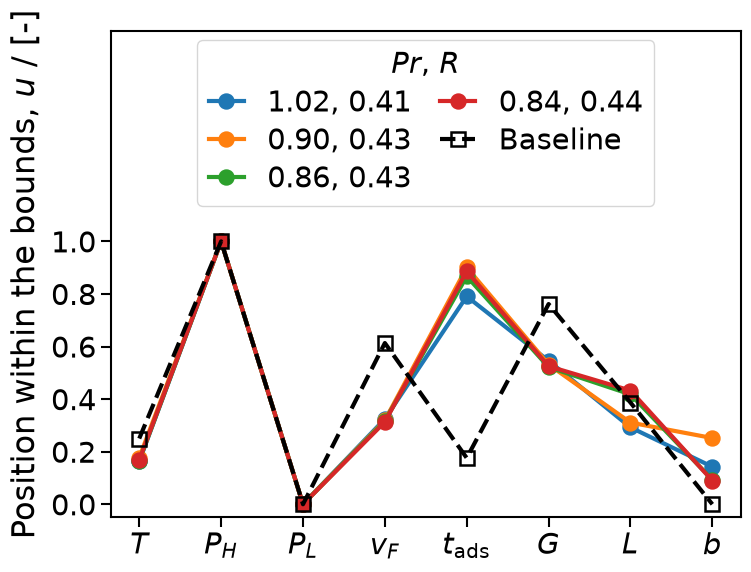

In [7]:
data = load_campaign()
front = data[data["pareto"]].sort_values("productivity_mmol", ascending=False)
shown = front.iloc[np.unique(np.linspace(0, len(front) - 1, min(len(front), 4)).round().astype(int))]
start = data[data["baseline"]].iloc[0]
labels = ["$T$", "$P_H$", "$P_L$", "$v_F$", r"$t_{\mathrm{ads}}$", "$G$", "$L$", "$b$"]
positions = np.arange(len(cycle.variables))

fig, ax = plt.subplots()
for k, (_, design) in enumerate(shown.iterrows()):
    ax.plot(positions, [design[f"unit_{name}"] for name in cycle.variables], color=f"C{k}", marker="o", markersize=10,
            label=f"{design['productivity_mmol']:.2f}, {design['recovery']:.2f}")
ax.plot(positions, [start[f"unit_{name}"] for name in cycle.variables], color="k", linestyle="--", marker="s",
        markersize=10, markerfacecolor="none", label="Baseline")
ax.set_xticks(positions, labels)
ax.set_ylabel("Position within the bounds, $u$ / [-]")
# Room above the bounds for the legend, which would otherwise hide some of the setups.
ax.set_ylim(-0.05, 1.8)
ax.set_yticks(np.linspace(0.0, 1.0, 6))
# Productivity in mmol/(kg s) and recovery of each setup.
ax.legend(title="$Pr$, $R$", loc="upper center", ncol=2)
fig.tight_layout()
fig.savefig(FIGURES / "pareto_setups.pdf", dpi=300)
plt.show()